In [1]:
# 1. Import libraries and load the source dataset
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

file_path = "Sample_Superstore_Cleaned.xlsx"
if not os.path.exists(file_path):
    try:
        from google.colab import files
        uploaded = files.upload()
        file_path = next(iter(uploaded))
    except Exception:
        raise FileNotFoundError(
            "Place Sample_Superstore_Cleaned.xlsx in the same folder as this notebook."
        )

df = pd.read_excel(file_path)
df["Order Date"] = pd.to_datetime(df["Order Date"])
df["Ship Date"] = pd.to_datetime(df["Ship Date"])

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (10194, 21)


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country/Region,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,US-2023-103800,2023-01-03,2023-01-07,Standard Class,DP-13000,Darren Powers,Consumer,United States,Houston,...,77095,Central,OFF-PA-10000174,Office Supplies,Paper,"Message Book, Wirebound, Four 5 1/2"" X 4"" Form...",16.448,2,0.2,5.5512
1,2,US-2023-112326,2023-01-04,2023-01-08,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,...,60540,Central,OFF-BI-10004094,Office Supplies,Binders,GBC Standard Plastic Binding Systems Combs,3.540,2,0.8,-5.4870
2,3,US-2023-112326,2023-01-04,2023-01-08,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,...,60540,Central,OFF-LA-10003223,Office Supplies,Labels,Avery 508,11.784,3,0.2,4.2717
3,4,US-2023-112326,2023-01-04,2023-01-08,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,...,60540,Central,OFF-ST-10002743,Office Supplies,Storage,SAFCO Boltless Steel Shelving,272.736,3,0.2,-64.7748
4,5,US-2023-141817,2023-01-05,2023-01-12,Standard Class,MB-18085,Mick Brown,Consumer,United States,Philadelphia,...,19143,East,OFF-AR-10003478,Office Supplies,Art,Avery Hi-Liter EverBold Pen Style Fluorescent ...,19.536,3,0.2,4.8840


In [2]:
# 2. Inspect fields and calculate the main KPIs
print("Columns:", df.columns.tolist())
print("\\nData types:")
display(df.dtypes.astype(str).rename("Data Type").to_frame())

total_records = len(df)
total_sales = df["Sales"].sum()
total_profit = df["Profit"].sum()
distinct_orders = df["Order ID"].nunique()
aov = total_sales / distinct_orders
profit_margin = (total_profit / total_sales) * 100
distinct_customers = df["Customer ID"].nunique()

kpi_summary = pd.DataFrame({
    "KPI": ["Total Records", "Distinct Order Volume", "Total Sales", "Total Profit",
            "Overall Profit Margin (%)", "Average Order Value (AOV)", "Distinct Customers"],
    "Calculated Value": [total_records, distinct_orders, total_sales, total_profit,
                         profit_margin, aov, distinct_customers]
})
display(kpi_summary.round(2))

Columns: ['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode', 'Customer ID', 'Customer Name', 'Segment', 'Country/Region', 'City', 'State/Province', 'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category', 'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit']
\nData types:


,Data Type
Row ID,int64
Order ID,object
Order Date,datetime64[ns]
Ship Date,datetime64[ns]
Ship Mode,object
Customer ID,object
Customer Name,object
Segment,object
Country/Region,object
City,object


,KPI,Calculated Value
0,Total Records,10194.00
1,Distinct Order Volume,5111.00
2,Total Sales,2326534.35
3,Total Profit,292296.81
4,Overall Profit Margin (%),12.56
5,Average Order Value (AOV),455.20
6,Distinct Customers,804.00


In [3]:
# 3. Annual sales, profit, order volume and growth
df["Year"] = df["Order Date"].dt.year
annual_summary = df.groupby("Year").agg(
    Revenue=("Sales", "sum"),
    Profit=("Profit", "sum"),
    Distinct_Orders=("Order ID", "nunique"),
    Records=("Order ID", "size")
).reset_index()

annual_summary["Revenue_Growth_%"] = annual_summary["Revenue"].pct_change() * 100
annual_summary["Profit_Margin_%"] = annual_summary["Profit"] / annual_summary["Revenue"] * 100
display(annual_summary.round(2))

,Year,Revenue,Profit,Distinct_Orders,Records,Revenue_Growth_%,Profit_Margin_%
0,2023,494040.21,51684.30,995,2051,NaN,10.46
1,2024,472993.03,62020.97,1053,2130,-4.26,13.11
2,2025,613933.58,82665.20,1340,2634,29.80,13.46
3,2026,745567.53,95926.35,1723,3379,21.44,12.87


In [4]:
# 4. Regional, category and shipping-mode summaries
def make_summary(field):
    result = df.groupby(field).agg(
        Sales=("Sales", "sum"),
        Profit=("Profit", "sum"),
        Quantity=("Quantity", "sum"),
        Distinct_Orders=("Order ID", "nunique")
    ).reset_index()
    result["Profit_Margin_%"] = result["Profit"] / result["Sales"] * 100
    return result.sort_values("Sales", ascending=False)

regional_summary = make_summary("Region")
category_summary = make_summary("Category")
shipping_summary = make_summary("Ship Mode")

print("Regional performance")
display(regional_summary.round(2))
print("Category performance")
display(category_summary.round(2))
print("Shipping mode performance")
display(shipping_summary.round(2))

Regional performance


,Region,Sales,Profit,Quantity,Distinct_Orders,Profit_Margin_%
3,West,739813.61,110798.82,12466,1635,14.98
1,East,691828.17,94883.26,11159,1475,13.71
0,Central,503170.67,39865.31,8820,1179,7.92
2,South,391721.90,46749.43,6209,822,11.93


Category performance


,Category,Sales,Profit,Quantity,Distinct_Orders,Profit_Margin_%
2,Technology,839893.28,146543.38,7017,1560,17.45
0,Furniture,754747.76,19730.00,8369,1819,2.61
1,Office Supplies,731893.31,126023.44,23268,3812,17.22


Shipping mode performance


,Ship Mode,Sales,Profit,Quantity,Distinct_Orders,Profit_Margin_%
3,Standard Class,1378840.55,168161.21,23409,3068,12.20
2,Second Class,466671.11,58962.13,7546,982,12.63
0,First Class,351750.74,49012.72,5724,795,13.93
1,Same Day,129271.96,16160.75,1975,266,12.50


In [5]:
# 5. Data quality and KPI validation checks
validation = pd.DataFrame([
    ["Rows", len(df), "Source record count"],
    ["Columns", df.shape[1], "Source field count"],
    ["Missing values (all columns)", int(df.isna().sum().sum()), "Expected 0 in cleaned file"],
    ["Duplicate Row IDs", int(df["Row ID"].duplicated().sum()), "Expected 0"],
    ["Duplicate full rows", int(df.duplicated().sum()), "Expected 0"],
    ["Missing Order IDs", int(df["Order ID"].isna().sum()), "Expected 0"],
    ["Missing Sales", int(df["Sales"].isna().sum()), "Expected 0"],
    ["Missing Profit", int(df["Profit"].isna().sum()), "Expected 0"],
    ["Ship Date before Order Date", int((df["Ship Date"] < df["Order Date"]).sum()), "Expected 0"],
    ["Zero Sales records", int((df["Sales"] == 0).sum()), "Review if non-zero"],
    ["Negative-Profit records", int((df["Profit"] < 0).sum()), "Retain; these can represent losses"],
    ["Zero-Profit records", int((df["Profit"] == 0).sum()), "Retain"],
    ["Distinct Order IDs", int(df["Order ID"].nunique()), "Used for order volume and AOV"],
    ["Total Sales", float(df["Sales"].sum()), "Must equal sum of Sales"],
    ["Total Profit", float(df["Profit"].sum()), "Must equal sum of Profit"],
    ["AOV", float(df["Sales"].sum() / df["Order ID"].nunique()), "Total Sales / distinct orders"],
    ["Overall Profit Margin (%)", float(df["Profit"].sum() / df["Sales"].sum() * 100), "Total Profit / Total Sales × 100"]
], columns=["Check", "Result", "Interpretation"])
display(validation)

,Check,Result,Interpretation
0,Rows,1.019400e+04,Source record count
1,Columns,2.200000e+01,Source field count
2,Missing values (all columns),0.000000e+00,Expected 0 in cleaned file
3,Duplicate Row IDs,0.000000e+00,Expected 0
4,Duplicate full rows,0.000000e+00,Expected 0
5,Missing Order IDs,0.000000e+00,Expected 0
6,Missing Sales,0.000000e+00,Expected 0
7,Missing Profit,0.000000e+00,Expected 0
8,Ship Date before Order Date,0.000000e+00,Expected 0
9,Zero Sales records,0.000000e+00,Review if non-zero


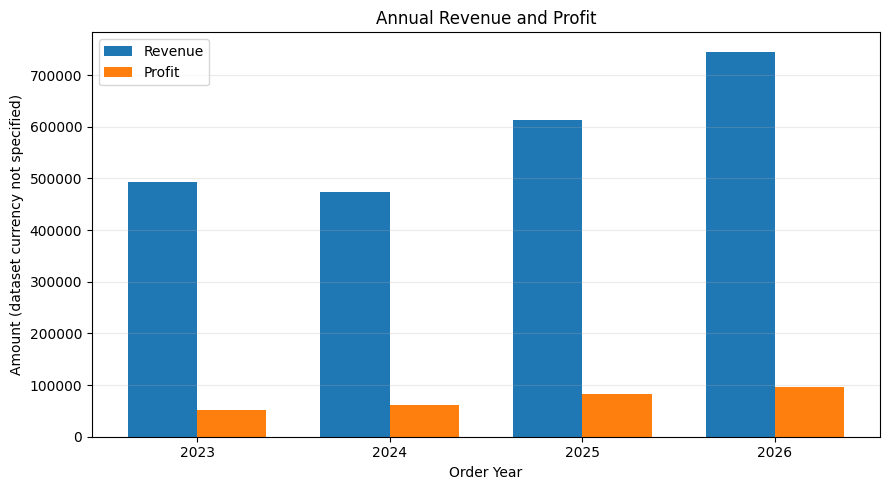

In [6]:
# Visual 1: Annual revenue and profit
fig, ax = plt.subplots(figsize=(9, 5))
x = annual_summary["Year"].astype(str)
width = 0.36
positions = np.arange(len(x))
ax.bar(positions - width/2, annual_summary["Revenue"], width, label="Revenue")
ax.bar(positions + width/2, annual_summary["Profit"], width, label="Profit")
ax.set_xticks(positions)
ax.set_xticklabels(x)
ax.set_title("Annual Revenue and Profit")
ax.set_xlabel("Order Year")
ax.set_ylabel("Amount (dataset currency not specified)")
ax.legend()
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

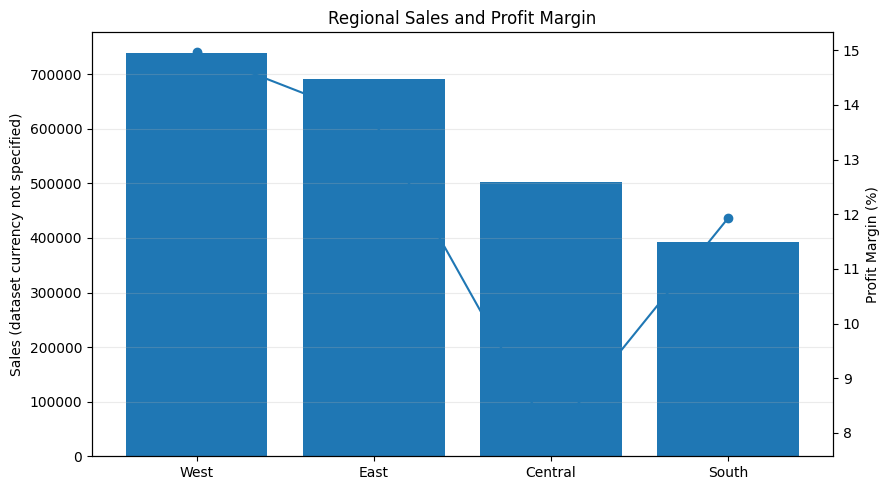

In [7]:
# Visual 2: Regional sales and profit margin
fig, ax1 = plt.subplots(figsize=(9, 5))
regions = regional_summary.sort_values("Sales", ascending=False)
ax1.bar(regions["Region"], regions["Sales"], label="Sales")
ax1.set_ylabel("Sales (dataset currency not specified)")
ax1.set_title("Regional Sales and Profit Margin")
ax2 = ax1.twinx()
ax2.plot(regions["Region"], regions["Profit_Margin_%"], marker="o", label="Profit Margin (%)")
ax2.set_ylabel("Profit Margin (%)")
ax1.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

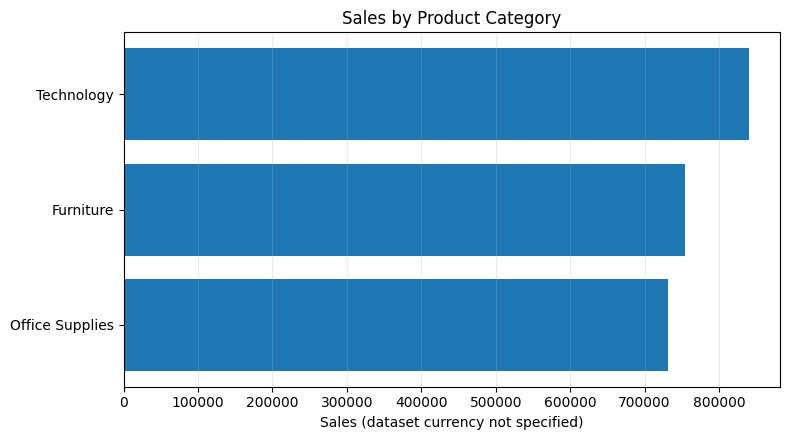

In [8]:
# Visual 3: Sales by product category
cats = category_summary.sort_values("Sales", ascending=True)
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(cats["Category"], cats["Sales"])
ax.set_title("Sales by Product Category")
ax.set_xlabel("Sales (dataset currency not specified)")
ax.grid(axis="x", alpha=0.25)
plt.tight_layout()
plt.show()

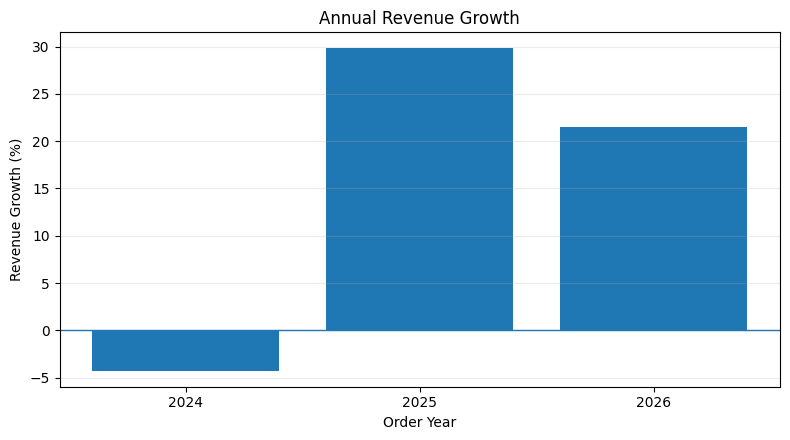

In [9]:
# Visual 4: Revenue growth by year (first year is the baseline)
growth = annual_summary.dropna(subset=["Revenue_Growth_%"])
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.bar(growth["Year"].astype(str), growth["Revenue_Growth_%"])
ax.axhline(0, linewidth=1)
ax.set_title("Annual Revenue Growth")
ax.set_xlabel("Order Year")
ax.set_ylabel("Revenue Growth (%)")
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()